# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Original numbered course notebook, adapted for Colab. Run in numerical order: later lessons load models trained by earlier lessons. Use the same Drive result folder across sessions. W&B logs stay offline. Full training can exceed a free Colab session; QUICK_RUN does not shorten these original Part 2 experiments.

Source: https://github.com/fastai/course22p2/blob/df9323235bc395b5c2f58a3d08b83761947b9b93/nbs/02_meanshift.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '04_fastai_part2', 'part2', '02_meanshift.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/04_fastai_part2
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/04_fastai_part2/results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.
- Retain original datasets, model definitions, training schedules and instructional comparisons.
- Run prerequisite checkpoint-producing notebooks first; do not replace missing weights with untrained models.

- Execute the CPU/GPU k-means comparison on the original clustering data; preserve timing samples, agreement/inertia checks and the cluster plot.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.


In [2]:
MAX_BATCH_SIZE = 32  #@param {type:"integer"}
# Increase on a larger GPU to match the original batch sizes.
assert MAX_BATCH_SIZE > 0

# Clustering

Clustering techniques are unsupervised learning algorithms that try to group unlabelled data into "clusters", using the (typically spatial) structure of the data itself. It has many [applications](https://en.wikipedia.org/wiki/Cluster_analysis#Applications).

The easiest way to demonstrate how clustering works is to simply generate some data and show them in action. We'll start off by importing the libraries we'll be using today.

In [3]:
import math, matplotlib.pyplot as plt, operator, torch
from functools import partial

In [4]:
torch.manual_seed(42)
torch.set_printoptions(precision=3, linewidth=140, sci_mode=False)

## Create data

In [5]:
n_clusters=6
n_samples =250

To generate our data, we're going to pick 6 random points, which we'll call centroids, and for each point we're going to generate 250 random points about it.

In [6]:
centroids = torch.rand(n_clusters, 2)*70-35

In [7]:
from torch.distributions.multivariate_normal import MultivariateNormal
from torch import tensor

In [8]:
def sample(m): return MultivariateNormal(m, torch.diag(tensor([5.,5.]))).sample((n_samples,))

In [9]:
slices = [sample(c) for c in centroids]
data = torch.cat(slices)
data.shape

torch.Size([1500, 2])

Below we can see each centroid marked w/ X, and the coloring associated to each respective cluster.

In [10]:
def plot_data(centroids, data, n_samples, ax=None):
    if ax is None: _,ax = plt.subplots()
    for i, centroid in enumerate(centroids):
        samples = data[i*n_samples:(i+1)*n_samples]
        ax.scatter(samples[:,0], samples[:,1], s=1)
        ax.plot(*centroid, markersize=10, marker="x", color='k', mew=5)
        ax.plot(*centroid, markersize=5, marker="x", color='m', mew=2)

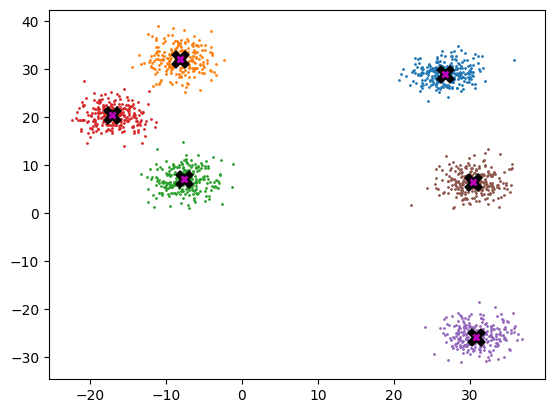

In [11]:
plot_data(centroids, data, n_samples)

## Mean shift

Most people that have come across clustering algorithms have learnt about **k-means**. Mean shift clustering is a newer and less well-known approach, but it has some important advantages:
* It doesn't require selecting the number of clusters in advance, but instead just requires a **bandwidth** to be specified, which can be easily chosen automatically
* It can handle clusters of any shape, whereas k-means (without using special extensions) requires that clusters be roughly ball shaped.

The algorithm is as follows:
* For each data point x in the sample X, find the distance between that point x and every other point in X
* Create weights for each point in X by using the **Gaussian kernel** of that point's distance to x
    * This weighting approach penalizes points further away from x
    * The rate at which the weights fall to zero is determined by the **bandwidth**, which is the standard deviation of the Gaussian
* Update x as the weighted average of all other points in X, weighted based on the previous step

This will iteratively push points that are close together even closer until they are next to each other.

In [12]:
midp = data.mean(0)
midp

tensor([ 9.222, 11.604])

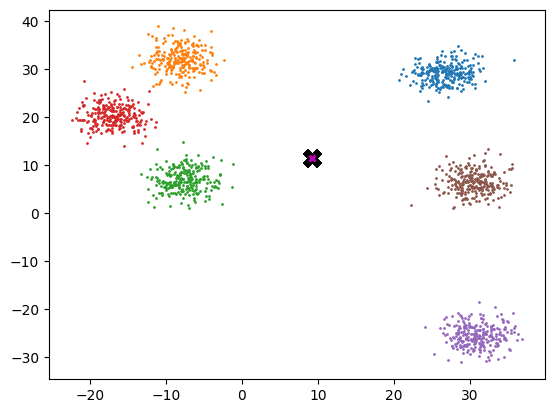

In [13]:
plot_data([midp]*6, data, n_samples)

So here's the definition of the gaussian kernel, which you may remember from high school...
 This person at the science march certainly remembered!

<img src="http://i.imgur.com/nijQLHw.jpg" width=400>

In [14]:
def gaussian(d, bw): return torch.exp(-0.5*((d/bw))**2) / (bw*math.sqrt(2*math.pi))

In [15]:
def plot_func(f):
    x = torch.linspace(0,10,100)
    plt.plot(x, f(x))

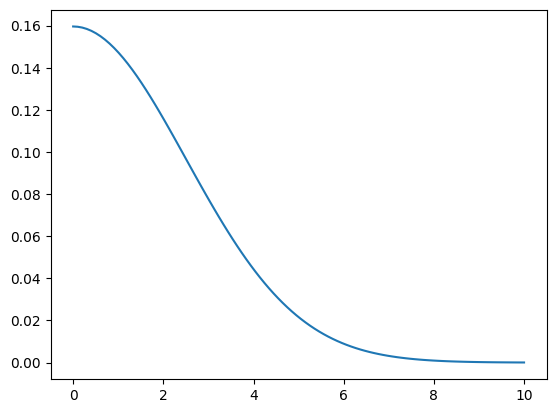

In [16]:
plot_func(partial(gaussian, bw=2.5))

In [17]:
partial

functools.partial

In our implementation, we choose the bandwidth to be 2.5. 

One easy way to choose bandwidth is to find which bandwidth covers one third of the data.

In [18]:
def tri(d, i): return (-d+i).clamp_min(0)/i

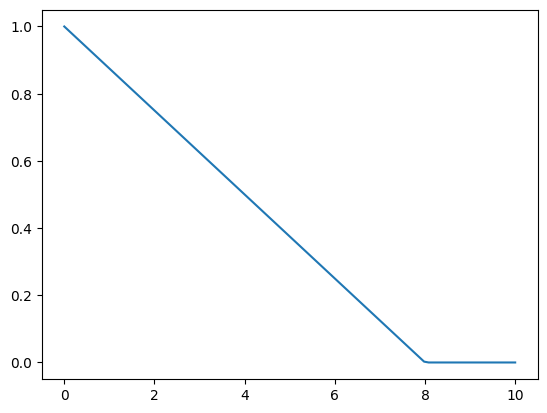

In [19]:
plot_func(partial(tri, i=8))

In [20]:
X = data.clone()
x = data[0]

In [21]:
x

tensor([26.204, 26.349])

In [22]:
x.shape,X.shape,x[None].shape

(torch.Size([2]), torch.Size([1500, 2]), torch.Size([1, 2]))

In [23]:
(x[None]-X)[:8]

tensor([[ 0.000,  0.000],
        [ 0.513, -3.865],
        [-4.227, -2.345],
        [ 0.557, -3.685],
        [-5.033, -3.745],
        [-4.073, -0.638],
        [-3.415, -5.601],
        [-1.920, -5.686]])

In [24]:
(x-X)[:8]

tensor([[ 0.000,  0.000],
        [ 0.513, -3.865],
        [-4.227, -2.345],
        [ 0.557, -3.685],
        [-5.033, -3.745],
        [-4.073, -0.638],
        [-3.415, -5.601],
        [-1.920, -5.686]])

In [25]:
# rewrite using torch.einsum
dist = ((x-X)**2).sum(1).sqrt()
dist[:8]

tensor([0.000, 3.899, 4.834, 3.726, 6.273, 4.122, 6.560, 6.002])

In [26]:
weight = gaussian(dist, 2.5)
weight

tensor([0.160, 0.047, 0.025,  ..., 0.000, 0.000, 0.000])

In [27]:
weight.shape,X.shape

(torch.Size([1500]), torch.Size([1500, 2]))

In [28]:
weight[:,None].shape

torch.Size([1500, 1])

In [29]:
weight[:,None]*X

tensor([[4.182, 4.205],
        [1.215, 1.429],
        [0.749, 0.706],
        ...,
        [0.000, 0.000],
        [0.000, 0.000],
        [0.000, 0.000]])

In [30]:
def one_update(X):
    for i, x in enumerate(X):
        dist = torch.sqrt(((x-X)**2).sum(1))
#         weight = gaussian(dist, 2.5)
        weight = tri(dist, 8)
        X[i] = (weight[:,None]*X).sum(0)/weight.sum()

In [31]:
def meanshift(data):
    X = data.clone()
    for it in range(5): one_update(X)
    return X

In [32]:
%time X=meanshift(data)

CPU times: user 974 ms, sys: 0 ns, total: 974 ms
Wall time: 974 ms


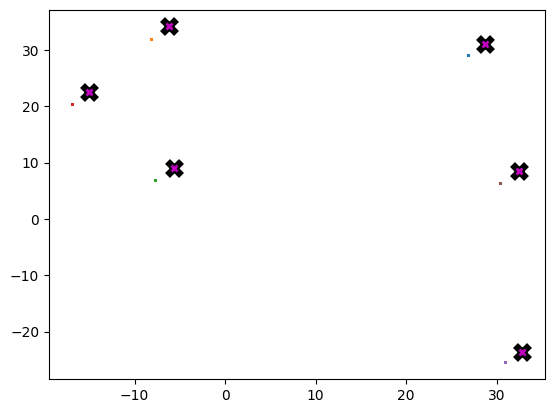

In [33]:
plot_data(centroids+2, X, n_samples)

## Animation

In [34]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [35]:
def do_one(d):
    if d: one_update(X)
    ax.clear()
    plot_data(centroids+2, X, n_samples, ax=ax)

In [36]:
# create your own animation
X = data.clone()
fig,ax = plt.subplots()
ani = FuncAnimation(fig, do_one, frames=5, interval=500, repeat=False)
plt.close()
HTML(ani.to_jshtml())

## GPU batched algorithm

To truly accelerate the algorithm, we need to be performing updates on a batch of points per iteration, instead of just one as we were doing.

In [37]:
bs = min(5, MAX_BATCH_SIZE)
X = data.clone()
x = X[:bs]
x.shape,X.shape

(torch.Size([5, 2]), torch.Size([1500, 2]))

In [38]:
def dist_b(a,b): return (((a[None]-b[:,None])**2).sum(2)).sqrt()

In [39]:
dist_b(X, x)

tensor([[ 0.000,  3.899,  4.834,  ..., 17.628, 22.610, 21.617],
        [ 3.899,  0.000,  4.978,  ..., 21.499, 26.508, 25.500],
        [ 4.834,  4.978,  0.000,  ..., 19.373, 24.757, 23.396],
        [ 3.726,  0.185,  4.969,  ..., 21.335, 26.336, 25.333],
        [ 6.273,  5.547,  1.615,  ..., 20.775, 26.201, 24.785]])

In [40]:
dist_b(X, x).shape

torch.Size([5, 1500])

In [41]:
X[None,:].shape, x[:,None].shape, (X[None,:]-x[:,None]).shape

(torch.Size([1, 1500, 2]), torch.Size([5, 1, 2]), torch.Size([5, 1500, 2]))

In [42]:
weight = gaussian(dist_b(X, x), 2)
weight

tensor([[0.199, 0.030, 0.011,  ..., 0.000, 0.000, 0.000],
        [0.030, 0.199, 0.009,  ..., 0.000, 0.000, 0.000],
        [0.011, 0.009, 0.199,  ..., 0.000, 0.000, 0.000],
        [0.035, 0.199, 0.009,  ..., 0.000, 0.000, 0.000],
        [0.001, 0.004, 0.144,  ..., 0.000, 0.000, 0.000]])

In [43]:
weight.shape,X.shape

(torch.Size([5, 1500]), torch.Size([1500, 2]))

In [44]:
weight[...,None].shape, X[None].shape

(torch.Size([5, 1500, 1]), torch.Size([1, 1500, 2]))

In [45]:
num = (weight[...,None]*X[None]).sum(1)
num.shape

torch.Size([5, 2])

In [46]:
num

tensor([[367.870, 386.231],
        [518.332, 588.680],
        [329.665, 330.782],
        [527.617, 598.217],
        [231.302, 234.155]])

In [47]:
torch.einsum('ij,jk->ik', weight, X)

tensor([[367.870, 386.231],
        [518.332, 588.680],
        [329.665, 330.782],
        [527.617, 598.218],
        [231.302, 234.155]])

In [48]:
weight@X

tensor([[367.870, 386.231],
        [518.332, 588.680],
        [329.665, 330.782],
        [527.617, 598.218],
        [231.302, 234.155]])

In [49]:
div = weight.sum(1, keepdim=True)
div.shape

torch.Size([5, 1])

In [50]:
num/div

tensor([[26.376, 27.692],
        [26.101, 29.643],
        [28.892, 28.990],
        [26.071, 29.559],
        [29.323, 29.685]])

In [51]:
def meanshift(data, bs = min(500, MAX_BATCH_SIZE)):
    n = len(data)
    X = data.clone()
    for it in range(5):
        for i in range(0, n, bs):
            s = slice(i, min(i+bs,n))
            weight = gaussian(dist_b(X, X[s]), 2.5)
#             weight = tri(dist_b(X, X[s]), 8)
            div = weight.sum(1, keepdim=True)
            X[s] = weight@X/div
    return X

Although each iteration still has to launch a new cuda kernel, there are now fewer iterations, and the acceleration from updating a batch of points more than makes up for it.

In [52]:
data = data.cuda()

In [53]:
X = meanshift(data).cpu()

In [54]:
%timeit -n 5 _=meanshift(data, 1250).cpu()

6.32 ms ± 102 µs per loop (mean ± std. dev. of 7 runs, 5 loops each)


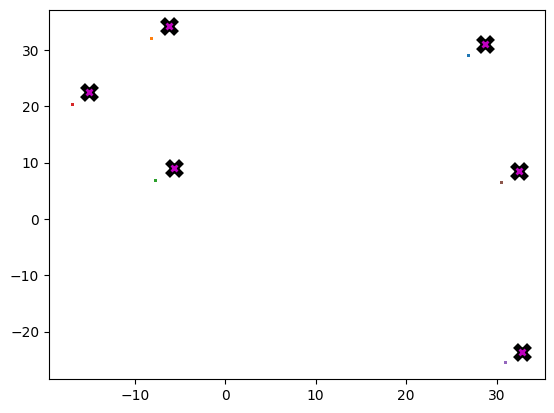

In [55]:
plot_data(centroids+2, X, n_samples)

**Homework:** implement k-means clustering, dbscan, locality sensitive hashing, or some other clustering, fast nearest neighbors, or similar algorithm of your choice, on the GPU. Check if your version is faster than a pure python or CPU version.

Bonus: Implement it in APL too!

Super bonus: Invent a new meanshift algorithm which picks only the closest points, to avoid quadratic time.

Super super bonus: Publish a paper that describes it :D

### Objective homework implementation

The next cell implements GPU k-means and the same fixed-iteration CPU algorithm on the original course points. It retains synchronized timing repetitions, transfer-inclusive timings, numerical/partition agreement, inertia and a plot. It reports the observed speed difference even if CPU is faster. Optional APL, new-algorithm and publication bonuses remain separate.


{
  "algorithm": "Lloyd k-means",
  "source_data": "original generated course clustering points",
  "rows": 1500,
  "dimensions": 2,
  "clusters": 6,
  "iterations": 30,
  "repeats": 5,
  "initial_indices": [
    979,
    1157,
    649,
    1287,
    657,
    133
  ],
  "gpu": "Tesla T4",
  "cpu_seconds": [
    0.020203388000481937,
    0.021491205999154772,
    0.02099277599972993,
    0.0224440419997336,
    0.030778006999753416
  ],
  "gpu_compute_seconds": [
    0.011634079000032216,
    0.010304738000741054,
    0.011285885000688722,
    0.011080452999522095,
    0.01188976299999922
  ],
  "gpu_with_transfers_seconds": [
    0.010620019000270986,
    0.009883523999633326,
    0.01042136300020502,
    0.011555859000509372,
    0.010130057999958808
  ],
  "cpu_median_seconds": 0.021491205999154772,
  "gpu_median_seconds": 0.011285885000688722,
  "compute_speedup": 1.90425527088423,
  "transfer_inclusive_speedup": 2.0622260253991707,
  "gpu_was_faster": true,
  "cpu_gpu_adjusted_rand

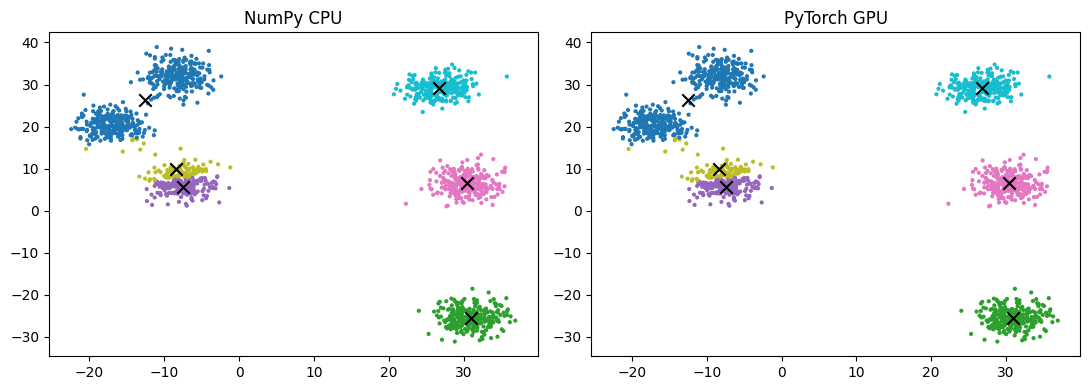

In [56]:
# Homework: batched Lloyd k-means on GPU, compared with the same NumPy CPU algorithm.
import json, time, statistics
from pathlib import Path
import numpy as np
from sklearn.metrics import adjusted_rand_score

@torch.no_grad()
def gpu_kmeans(points, initial_centres, iterations=30):
    centres=initial_centres.clone()
    for _ in range(iterations):
        distances=(points[:,None,:]-centres[None,:,:]).square().sum(-1)
        labels=distances.argmin(1)
        totals=torch.zeros_like(centres)
        totals.scatter_add_(0,labels[:,None].expand_as(points),points)
        counts=torch.bincount(labels,minlength=len(centres))[:,None]
        centres=torch.where(counts>0,totals/counts.clamp_min(1),centres)
    labels=(points[:,None,:]-centres[None,:,:]).square().sum(-1).argmin(1)
    inertia=(points-centres[labels]).square().sum()
    return centres,labels,inertia

def cpu_kmeans(points, initial_centres, iterations=30):
    centres=initial_centres.copy()
    for _ in range(iterations):
        labels=((points[:,None,:]-centres[None,:,:])**2).sum(-1).argmin(1)
        totals=np.zeros_like(centres)
        np.add.at(totals,labels,points)
        counts=np.bincount(labels,minlength=len(centres))[:,None]
        centres=np.where(counts>0,totals/np.maximum(counts,1),centres)
    labels=((points[:,None,:]-centres[None,:,:])**2).sum(-1).argmin(1)
    return centres,labels,float(((points-centres[labels])**2).sum())

assert torch.cuda.is_available(),'The GPU comparison requires a CUDA runtime.'
cpu_points=data.detach().cpu().numpy().astype(np.float32,copy=True)
initial_indices=np.random.default_rng(42).choice(len(cpu_points),n_clusters,replace=False)
initial_cpu=cpu_points[initial_indices].copy()
gpu_points=torch.from_numpy(cpu_points).cuda()
initial_gpu=torch.from_numpy(initial_cpu).cuda()
iterations=30
# Warm both implementations; synchronize around every GPU timing boundary.
cpu_kmeans(cpu_points,initial_cpu,iterations)
gpu_kmeans(gpu_points,initial_gpu,iterations);torch.cuda.synchronize()
cpu_times=[];gpu_times=[];transfer_times=[]
for _ in range(5):
    start=time.perf_counter();cpu_result=cpu_kmeans(cpu_points,initial_cpu,iterations)
    cpu_times.append(time.perf_counter()-start)
    torch.cuda.synchronize();start=time.perf_counter()
    gpu_result=gpu_kmeans(gpu_points,initial_gpu,iterations)
    torch.cuda.synchronize();gpu_times.append(time.perf_counter()-start)
    torch.cuda.synchronize();start=time.perf_counter()
    transferred=gpu_kmeans(torch.from_numpy(cpu_points).cuda(),torch.from_numpy(initial_cpu).cuda(),iterations)
    transferred_cpu=tuple(value.cpu() for value in transferred)
    torch.cuda.synchronize();transfer_times.append(time.perf_counter()-start)

gpu_centres,gpu_labels,gpu_inertia=(value.cpu() for value in gpu_result)
agreement=adjusted_rand_score(cpu_result[1],gpu_labels.numpy())
assert agreement>.99,'Investigate CPU/GPU clustering disagreement before interpreting speed.'
assert np.isclose(cpu_result[2],float(gpu_inertia),rtol=1e-4,atol=1e-3)
cpu_median=statistics.median(cpu_times);gpu_median=statistics.median(gpu_times)
evidence={'algorithm':'Lloyd k-means','source_data':'original generated course clustering points',
 'rows':len(cpu_points),'dimensions':cpu_points.shape[1],'clusters':n_clusters,'iterations':iterations,
 'repeats':5,'initial_indices':initial_indices.tolist(),'gpu':torch.cuda.get_device_name(),
 'cpu_seconds':cpu_times,'gpu_compute_seconds':gpu_times,'gpu_with_transfers_seconds':transfer_times,
 'cpu_median_seconds':cpu_median,'gpu_median_seconds':gpu_median,
 'compute_speedup':cpu_median/gpu_median,'transfer_inclusive_speedup':cpu_median/statistics.median(transfer_times),
 'gpu_was_faster':gpu_median<cpu_median,'cpu_gpu_adjusted_rand':float(agreement),
 'cpu_inertia':cpu_result[2],'gpu_inertia':float(gpu_inertia),
 'true_cluster_adjusted_rand':float(adjusted_rand_score(np.repeat(np.arange(n_clusters),n_samples),gpu_labels.numpy())),
 'bonus_apl_or_new_algorithm_claimed':False,'paper_publication_claimed':False}
results=Path('results');results.mkdir(exist_ok=True)
(results/'kmeans_cpu_gpu_comparison.json').write_text(json.dumps(evidence,indent=2))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,labels,centres,label in [(axes[0],cpu_result[1],cpu_result[0],'NumPy CPU'),(axes[1],gpu_labels.numpy(),gpu_centres.numpy(),'PyTorch GPU')]:
    ax.scatter(cpu_points[:,0],cpu_points[:,1],c=labels,s=4,cmap='tab10')
    ax.scatter(centres[:,0],centres[:,1],marker='x',c='black',s=80)
    ax.set_title(label)
fig.tight_layout();fig.savefig(results/'kmeans_cpu_gpu_clusters.png',dpi=150)
print(json.dumps(evidence,indent=2))
print('A small dataset may favor CPU because GPU kernel/transfer overhead dominates; the measured result is retained either way.')

Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [57]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [58]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "04_fastai_part2/02_meanshift.ipynb", "source_sha256": "1425415f7859bef944a524056b0c1592e04114817e65efdd3da93776527d763e", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "04_fastai_part2/miniai/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855", "04_fastai_part2/miniai/_modidx.py": "21ec4929aaeca2cde3710b3f069ff8032fc7e6fb57712052d3168abdb4d4d368", "